# Application for ECATS - Reproduction of ICAO/LTAG Scenarios

This document has been published for reproducing the application presented in a conference paper dedicated to AeroMAPS, focuding on the reproduction of ICAO LTAG scenarios. The different assumptions of this prospective scenario are given in the following. 

## Load and perimeter choice

In [1]:
%matplotlib widget

# The scenario ships with the package; copy it somewhere writable before running,
# so this notebook's outputs and regenerated inputs land in ./workdir rather than
# in the installed AeroMAPS.
from aeromaps.utils.scenarios import prepare_scenario
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import numpy as np
from aeromaps import create_process
import gc

## Process, data and compute

In [2]:
process_is0medium = create_process(
    configuration_file="data_ecats/config_files/config_is0medium.yaml"
)
process_is1medium = create_process(
    configuration_file="data_ecats/config_files/config_is1medium.yaml"
)
process_is2medium = create_process(
    configuration_file="data_ecats/config_files/config_is2medium.yaml"
)
process_is3medium = create_process(
    configuration_file="data_ecats/config_files/config_is3medium.yaml"
)

In [3]:
process_is0medium_update = create_process(
    configuration_file="data_ecats/config_files_update/config_is0medium.yaml"
)
process_is1medium_update = create_process(
    configuration_file="data_ecats/config_files_update/config_is1medium.yaml"
)
process_is2medium_update = create_process(
    configuration_file="data_ecats/config_files_update/config_is2medium.yaml"
)
process_is3medium_update = create_process(
    configuration_file="data_ecats/config_files_update/config_is3medium.yaml"
)
process_is3medium_update.parameters.h2_leakage_rate = 3.0  # [%]

In [4]:
process_is0medium_update_sulfur = create_process(
    configuration_file="data_ecats/config_files_update/config_is0medium_sulfur.yaml"
)
process_is1medium_update_sulfur = create_process(
    configuration_file="data_ecats/config_files_update/config_is1medium_sulfur.yaml"
)
process_is2medium_update_sulfur = create_process(
    configuration_file="data_ecats/config_files_update/config_is2medium_sulfur.yaml"
)
process_is3medium_update_sulfur = create_process(
    configuration_file="data_ecats/config_files_update/config_is3medium_sulfur.yaml"
)

In [5]:
process_is2medium_update_contrails = create_process(
    configuration_file="data_ecats/config_files_update/config_is2medium.yaml"
)
process_is2medium_update_contrails.parameters.operations_contrails_final_gain = 60.0  # [%]
process_is2medium_update_contrails.parameters.operations_contrails_final_overconsumption = 2.0  # [%]
process_is2medium_update_contrails.parameters.operations_contrails_start_year = 2035
process_is2medium_update_contrails.parameters.operations_contrails_duration = 15.0

process_is2medium_update_sulfur_contrails = create_process(
    configuration_file="data_ecats/config_files_update/config_is2medium_sulfur.yaml"
)
process_is2medium_update_sulfur_contrails.parameters.operations_contrails_final_gain = 60.0  # [%]
process_is2medium_update_sulfur_contrails.parameters.operations_contrails_final_overconsumption = 2.0  # [%]
process_is2medium_update_sulfur_contrails.parameters.operations_contrails_start_year = 2035
process_is2medium_update_sulfur_contrails.parameters.operations_contrails_duration = 15.0

process_is2medium_update_dac = create_process(
    configuration_file="data_ecats/config_files_update/config_is2medium_dac.yaml"
)
process_is2medium_update_dac.parameters.residual_carbon_offset_share_reference_years = [2020, 2021, 2022, 2023, 2024, 2025, 2026, 2027, 2028, 2029,
          2030, 2031, 2032, 2033, 2034, 2035, 2036, 2037, 2038, 2039,
          2040, 2041, 2042, 2043, 2044, 2045, 2046, 2047, 2048, 2049,
          2050, 2051, 2052, 2053, 2054, 2055, 2056, 2057, 2058, 2059,
          2060, 2061, 2062, 2063, 2064, 2065, 2066, 2067, 2068, 2069,
          2070]
process_is2medium_update_dac.parameters.residual_carbon_offset_share_reference_years_values = [1.3, 2.3, 3.1, 3.6, 4.1, 4.9, 5.9, 6.8, 7.9, 8.9,
           10.0, 11.8, 13.6, 15.5, 17.5, 19.6, 21.7, 23.9, 26.2, 28.7,
           30.9, 33.8, 36.6, 39.4, 42.2, 45.0, 47.6, 50.0, 52.3, 54.3,
           56.2, 56.5, 56.8, 57.2, 57.7, 58.1, 58.6, 59.1, 59.5, 60.0,
           60.5, 61.1, 61.6, 62.2, 62.9, 63.4, 63.9, 64.4, 64.9, 65.4,
           65.8]

process_is2medium_update_kero = create_process(
    configuration_file="data_ecats/config_files_update/config_is2medium_kero.yaml"
)

In [6]:
process_is0medium_keroht = create_process(
    configuration_file="data_ecats/config_files/config_is0medium_keroht.yaml"
)
process_is0medium_update_keroht = create_process(
    configuration_file="data_ecats/config_files_update/config_is0medium_keroht.yaml"
)
process_is0medium_keroht_vpm = create_process(
    configuration_file="data_ecats/config_files/config_is0medium_keroht.yaml"
)
process_is0medium_keroht_vpm.parameters.karcher_curve_case = "High vPM"
process_is0medium_update_keroht_vpm = create_process(
    configuration_file="data_ecats/config_files_update/config_is0medium_keroht.yaml"
)
process_is0medium_update_keroht_vpm.parameters.karcher_curve_case = "High vPM"

In [7]:
# # IS0 scenarios
process_is0medium.compute()
process_is0medium_data = process_is0medium.data
process_is0medium.write_json()
del process_is0medium
gc.collect()

process_is0medium_update.compute()
process_is0medium_update_data = process_is0medium_update.data
process_is0medium_update.write_json()
del process_is0medium_update
gc.collect()

process_is0medium_update_sulfur.compute()
process_is0medium_update_sulfur_data = process_is0medium_update_sulfur.data
process_is0medium_update_sulfur.write_json()
del process_is0medium_update_sulfur
gc.collect()

process_is0medium_keroht.compute()
process_is0medium_keroht_data = process_is0medium_keroht.data
process_is0medium_keroht.write_json()
del process_is0medium_keroht
gc.collect()

process_is0medium_update_keroht.compute()
process_is0medium_update_keroht_data = process_is0medium_update_keroht.data
process_is0medium_update_keroht.write_json()
del process_is0medium_update_keroht
gc.collect()

process_is0medium_keroht_vpm.compute()
process_is0medium_keroht_vpm_data = process_is0medium_keroht_vpm.data
process_is0medium_keroht_vpm.write_json()
del process_is0medium_keroht_vpm
gc.collect()

process_is0medium_update_keroht_vpm.compute()
process_is0medium_update_keroht_vpm_data = process_is0medium_update_keroht_vpm.data
process_is0medium_update_keroht_vpm.write_json()
del process_is0medium_update_keroht_vpm
gc.collect()

C:\Users\t.planes\PycharmProjects\AeroMAPS\aeromaps\core\gemseo.py:621: UserWarning: [LoadFactorMarket - short_range] The quadratic load-factor model was calibrated for a horizon of 31 years (end_year=2050, last_historical_year=2019). The current scenario has a horizon of 51 years (end_year=2070, last_historical_year=2019). The arrival-slope constraint (≈ 0 %/yr at end_year) is applied unchanged. For a model without this limitation, use LoadFactorMarketSimpleInterpolation (set global.load_factor.model: simple_interpolation in markets.yaml).
  return self.model.compute(input_data)
C:\Users\t.planes\PycharmProjects\AeroMAPS\aeromaps\core\gemseo.py:621: UserWarning: [LoadFactorMarket - medium_range] The quadratic load-factor model was calibrated for a horizon of 31 years (end_year=2050, last_historical_year=2019). The current scenario has a horizon of 51 years (end_year=2070, last_historical_year=2019). The arrival-slope constraint (≈ 0 %/yr at end_year) is applied unchanged. For a model 

58331

In [8]:
# IS1 scenarios
process_is1medium.compute()
process_is1medium_data = process_is1medium.data
process_is1medium.write_json()
del process_is1medium
gc.collect()

process_is1medium_update.compute()
process_is1medium_update_data = process_is1medium_update.data
process_is1medium_update.write_json()
del process_is1medium_update
gc.collect()

process_is1medium_update_sulfur.compute()
process_is1medium_update_sulfur_data = process_is1medium_update_sulfur.data
process_is1medium_update_sulfur.write_json()
del process_is1medium_update_sulfur
gc.collect()

C:\Users\t.planes\PycharmProjects\AeroMAPS\aeromaps\core\gemseo.py:621: UserWarning: [LoadFactorMarket - short_range] The quadratic load-factor model was calibrated for a horizon of 31 years (end_year=2050, last_historical_year=2019). The current scenario has a horizon of 51 years (end_year=2070, last_historical_year=2019). The arrival-slope constraint (≈ 0 %/yr at end_year) is applied unchanged. For a model without this limitation, use LoadFactorMarketSimpleInterpolation (set global.load_factor.model: simple_interpolation in markets.yaml).
  return self.model.compute(input_data)
C:\Users\t.planes\PycharmProjects\AeroMAPS\aeromaps\core\gemseo.py:621: UserWarning: [LoadFactorMarket - medium_range] The quadratic load-factor model was calibrated for a horizon of 31 years (end_year=2050, last_historical_year=2019). The current scenario has a horizon of 51 years (end_year=2070, last_historical_year=2019). The arrival-slope constraint (≈ 0 %/yr at end_year) is applied unchanged. For a model 

73832

In [9]:
# IS2 scenarios
process_is2medium.compute()
process_is2medium_data = process_is2medium.data
process_is2medium.write_json()
del process_is2medium
gc.collect()

process_is2medium_update.compute()
process_is2medium_update_data = process_is2medium_update.data
process_is2medium_update.write_json()

process_is2medium_update_sulfur.compute()
process_is2medium_update_sulfur_data = process_is2medium_update_sulfur.data
process_is2medium_update_sulfur.write_json()

process_is2medium_update_contrails.compute()
process_is2medium_update_contrails_data = process_is2medium_update_contrails.data
process_is2medium_update_contrails.write_json()
del process_is2medium_update_contrails
gc.collect()

process_is2medium_update_sulfur_contrails.compute()
process_is2medium_update_sulfur_contrails_data = process_is2medium_update_sulfur_contrails.data
process_is2medium_update_sulfur_contrails.write_json()

process_is2medium_update_dac.compute()
process_is2medium_update_dac_data = process_is2medium_update_dac.data
process_is2medium_update_dac.write_json()
del process_is2medium_update_dac
gc.collect()

process_is2medium_update_kero.compute()
process_is2medium_update_kero_data = process_is2medium_update_kero.data
process_is2medium_update_kero.write_json()
del process_is2medium_update_kero
gc.collect()

C:\Users\t.planes\PycharmProjects\AeroMAPS\aeromaps\core\gemseo.py:621: UserWarning: [LoadFactorMarket - short_range] The quadratic load-factor model was calibrated for a horizon of 31 years (end_year=2050, last_historical_year=2019). The current scenario has a horizon of 51 years (end_year=2070, last_historical_year=2019). The arrival-slope constraint (≈ 0 %/yr at end_year) is applied unchanged. For a model without this limitation, use LoadFactorMarketSimpleInterpolation (set global.load_factor.model: simple_interpolation in markets.yaml).
  return self.model.compute(input_data)
C:\Users\t.planes\PycharmProjects\AeroMAPS\aeromaps\core\gemseo.py:621: UserWarning: [LoadFactorMarket - medium_range] The quadratic load-factor model was calibrated for a horizon of 31 years (end_year=2050, last_historical_year=2019). The current scenario has a horizon of 51 years (end_year=2070, last_historical_year=2019). The arrival-slope constraint (≈ 0 %/yr at end_year) is applied unchanged. For a model 

54994

In [10]:
# IS3 scenarios
process_is3medium.compute()
process_is3medium_data = process_is3medium.data
process_is3medium.write_json()

process_is3medium_update.compute()
process_is3medium_update_data = process_is3medium_update.data
process_is3medium_update.write_json()

process_is3medium_update_sulfur.compute()
process_is3medium_update_sulfur_data = process_is3medium_update_sulfur.data
process_is3medium_update_sulfur.write_json()

C:\Users\t.planes\PycharmProjects\AeroMAPS\aeromaps\core\gemseo.py:621: UserWarning: [LoadFactorMarket - short_range] The quadratic load-factor model was calibrated for a horizon of 31 years (end_year=2050, last_historical_year=2019). The current scenario has a horizon of 51 years (end_year=2070, last_historical_year=2019). The arrival-slope constraint (≈ 0 %/yr at end_year) is applied unchanged. For a model without this limitation, use LoadFactorMarketSimpleInterpolation (set global.load_factor.model: simple_interpolation in markets.yaml).
  return self.model.compute(input_data)
C:\Users\t.planes\PycharmProjects\AeroMAPS\aeromaps\core\gemseo.py:621: UserWarning: [LoadFactorMarket - medium_range] The quadratic load-factor model was calibrated for a horizon of 31 years (end_year=2050, last_historical_year=2019). The current scenario has a horizon of 51 years (end_year=2070, last_historical_year=2019). The arrival-slope constraint (≈ 0 %/yr at end_year) is applied unchanged. For a model 

## Results

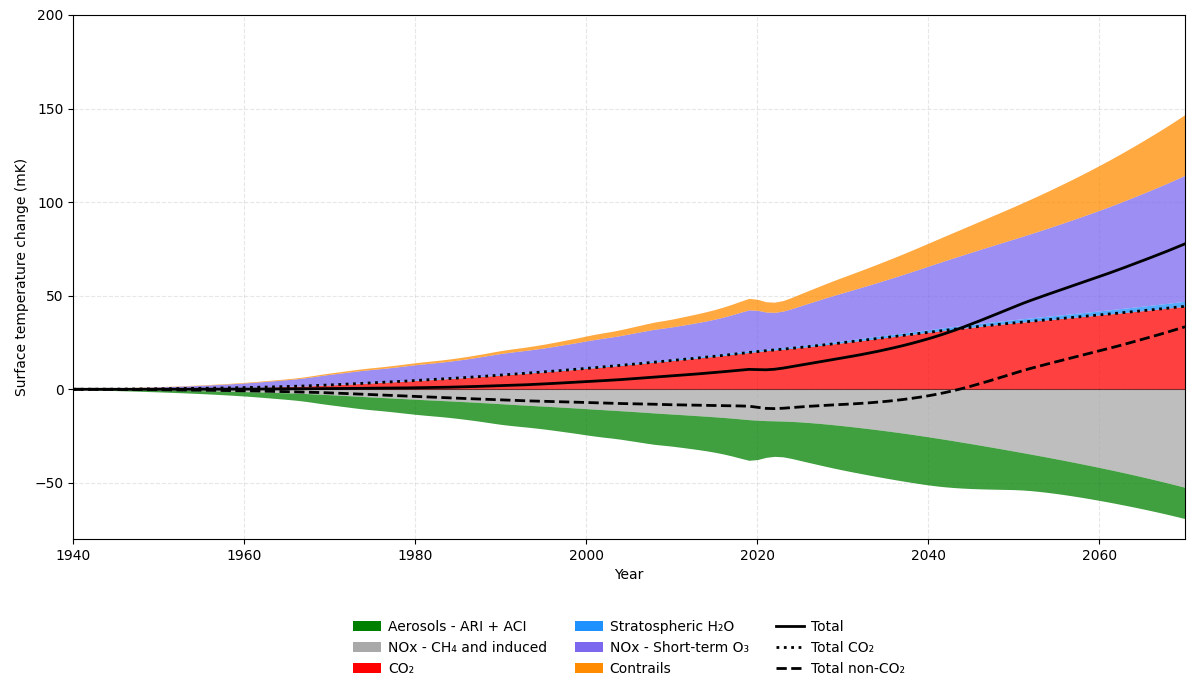

In [11]:
climate = process_is3medium.data["climate_outputs"]
climate = process_is3medium_update.data["climate_outputs"]
climate = process_is2medium_update.data["climate_outputs"]

# Contributions converties en mW/m² (1 W/m² = 1000 mW/m²)
metric = "temperature"
if metric=="rf":
    species = {
        "Aerosols - ARI + ACI": (climate["sulfur_rf"] + climate["soot_rf"]) * 1000,
        "NOx - CH₄ and induced": (
            climate["nox_ch4_decrease_rf"]
            + climate["nox_stratospheric_water_vapor_decrease_rf"]
            + climate["nox_long_term_o3_decrease_rf"]
        ) * 1000,
        "CO₂": climate["co2_rf"] * 1000,
        "Stratospheric H₂O": climate["h2o_rf"] * 1000,
        "NOx - Short-term O₃": climate["nox_short_term_o3_increase_rf"] * 1000,
        "Contrails": climate["contrails_rf"] * 1000,
    }
elif metric=="erf":
    species = {
        "Aerosols - ARI + ACI": (climate["sulfur_erf"] + climate["soot_erf"]) * 1000,
        "NOx - CH₄ and induced": (
            climate["nox_ch4_decrease_erf"]
            + climate["nox_stratospheric_water_vapor_decrease_erf"]
            + climate["nox_long_term_O₃_decrease_erf"]
        ) * 1000,
        "CO₂": climate["co2_erf"] * 1000,
        "Stratospheric H₂O": climate["h2o_erf"] * 1000,
        "NOx - Short-term O₃": climate["nox_short_term_o3_increase_erf"] * 1000,
        "Contrails": climate["contrails_erf"] * 1000,
    }
else:
    species = {
        "Aerosols - ARI + ACI": (climate["temperature_increase_from_sulfur_from_aviation"] + climate["temperature_increase_from_soot_from_aviation"]) * 1000,
        "NOx - CH₄ and induced": (
            climate["temperature_increase_from_nox_long_term_o3_decrease_from_aviation"]
            + climate["temperature_increase_from_nox_ch4_decrease_from_aviation"]
            + climate["temperature_increase_from_nox_stratospheric_water_vapor_decrease_from_aviation"]
        ) * 1000,
        "CO₂": climate["temperature_increase_from_co2_from_aviation"] * 1000,
        "Stratospheric H₂O": climate["temperature_increase_from_h2o_from_aviation"] * 1000,
        "NOx - Short-term O₃": climate["temperature_increase_from_nox_short_term_o3_increase_from_aviation"] * 1000,
        "Contrails": climate["temperature_increase_from_contrails_from_aviation"] * 1000,
    }
    

colors = {
    "Aerosols - ARI + ACI": "green",
    "NOx - CH₄ and induced": "darkgrey",
    "CO₂": "red",
    "Stratospheric H₂O": "dodgerblue",
    "NOx - Short-term O₃": "mediumslateblue",
    "Contrails": "darkorange",
}

species = {
    name: np.asarray(values, dtype=float).squeeze()
    for name, values in species.items()
}

# Axe temporel commençant en 1940
n = len(next(iter(species.values())))
x = np.arange(1940, 1940 + n)

fig, ax = plt.subplots(figsize=(12, 7))

positive_stack = np.zeros(n, dtype=float)
negative_stack = np.zeros(n, dtype=float)

# NOx négatif en bas, Aerosols au-dessus
negative_order = ["NOx - CH₄ and induced", "Aerosols - ARI + ACI"]
positive_order = ["CO₂", "Stratospheric H₂O", "NOx - Short-term O₃", "Contrails"]

# Empilement négatif
for name in negative_order:
    values = species[name]
    negative = np.minimum(values, 0)

    ax.fill_between(
        x,
        negative_stack,
        negative_stack + negative,
        color=colors[name],
        alpha=0.75,
        linewidth=0,
    )
    negative_stack += negative

# Empilement positif
for name in positive_order:
    values = species[name]
    positive = np.maximum(values, 0)

    ax.fill_between(
        x,
        positive_stack,
        positive_stack + positive,
        color=colors[name],
        alpha=0.75,
        linewidth=0,
    )
    positive_stack += positive

# Total net en mW/m²
total = np.sum(np.stack(list(species.values())), axis=0)

ax.plot(
    x,
    total,
    color="black",
    linewidth=2,
    zorder=10,
)

ax.axhline(0, color="black", linewidth=0.8, alpha=0.5)

# --- Totaux CO2 et non-CO2 ---
co2_total = species["CO₂"]

non_co2_total = total - co2_total

ax.plot(
    x,
    co2_total,
    color="black",
    linewidth=2,
    linestyle=":",
    zorder=9,
    label="Total CO₂"
)

ax.plot(
    x,
    non_co2_total,
    color="black",
    linewidth=2,
    linestyle="--",
    zorder=9,
    label="Total non-CO₂"
)


ax.set_xlabel("Year")
if metric=="rf":
    ax.set_ylabel("Radiative forcing (mW/m²)")
elif metric=="erf":
    ax.set_ylabel("Effective radiative forcing (mW/m²)")
else:
    ax.set_ylabel("Surface temperature change (mK)")


# Grille sur les deux axes
ax.grid(True, which="major", axis="both", alpha=0.3, linestyle="--")
ax.set_axisbelow(True)

# Légende
handles = [
    # Colonne 1
    Patch(facecolor="green", label="Aerosols - ARI + ACI"),
    Patch(facecolor="darkgrey", label="NOx - CH₄ and induced"),
    Patch(facecolor="red", label="CO₂"),

    # Colonne 2
    Patch(facecolor="dodgerblue", label="Stratospheric H₂O"),
    Patch(facecolor="mediumslateblue", label="NOx - Short-term O₃"),
    Patch(facecolor="darkorange", label="Contrails"),

    # Colonne 3 : les trois totaux
    Line2D([0], [0], color="black", linewidth=2,
           linestyle="-", label="Total"),
    Line2D([0], [0], color="black", linewidth=2,
           linestyle=":", label="Total CO₂"),
    Line2D([0], [0], color="black", linewidth=2,
           linestyle="--", label="Total non-CO₂"),
]

ax.legend(
    handles=handles,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.13),
    ncol=3,
    frameon=False,
    columnspacing=2.0,
    handletextpad=0.5
)
plt.tight_layout()
fig.subplots_adjust(bottom=0.23)
plt.xlim(1940, 2070)
if metric=="rf":
    plt.ylim(-80, 220)
elif metric=="erf":
    plt.ylim(-80, 150)
else:
    plt.ylim(-40, 80)

plt.ylim(-80, 200)
    
plt.show()

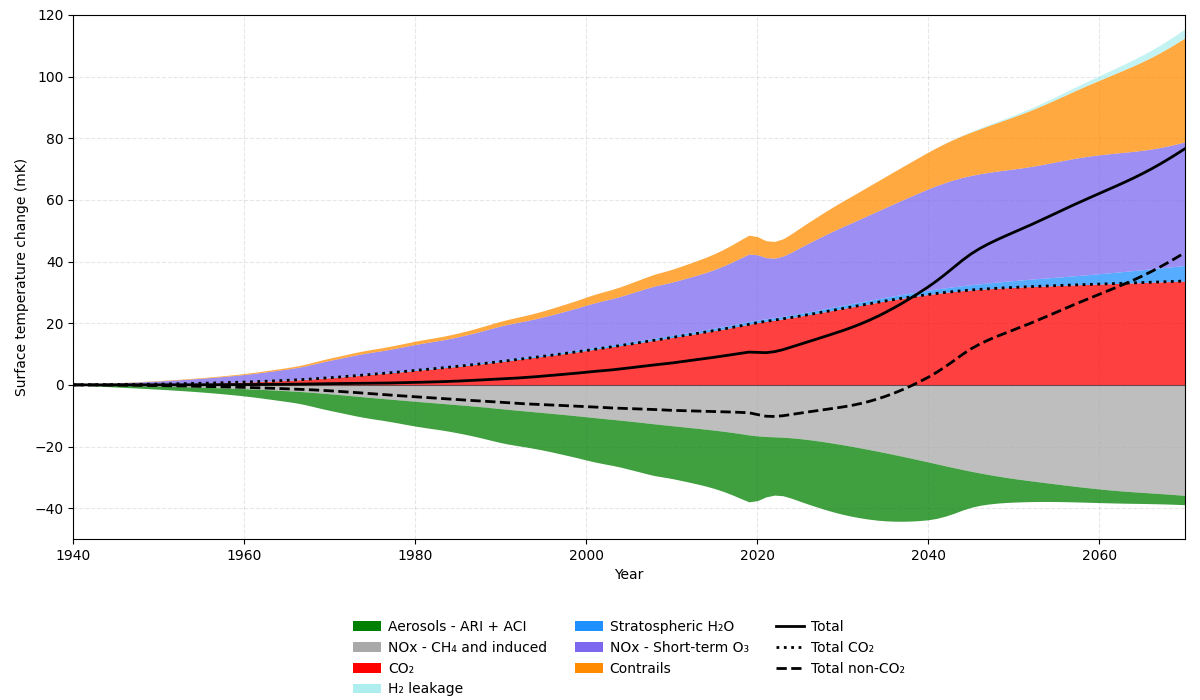

In [12]:
climate = process_is3medium_update.data["climate_outputs"]

species = {
    "Aerosols - ARI + ACI": (climate["temperature_increase_from_sulfur_from_aviation"] + climate["temperature_increase_from_soot_from_aviation"]) * 1000,
    "NOx - CH₄ and induced": (
        climate["temperature_increase_from_nox_long_term_o3_decrease_from_aviation"]
        + climate["temperature_increase_from_nox_ch4_decrease_from_aviation"]
        + climate["temperature_increase_from_nox_stratospheric_water_vapor_decrease_from_aviation"]
    ) * 1000,
    "CO₂": climate["temperature_increase_from_co2_from_aviation"] * 1000,
    "Stratospheric H₂O": climate["temperature_increase_from_h2o_from_aviation"] * 1000,
    "NOx - Short-term O₃": climate["temperature_increase_from_nox_short_term_o3_increase_from_aviation"] * 1000,
    "Contrails": climate["temperature_increase_from_contrails_from_aviation"] * 1000,
    "H₂ leakage": climate["temperature_increase_from_h2_leakage_from_aviation"] * 1000,
}
    

colors = {
    "Aerosols - ARI + ACI": "green",
    "NOx - CH₄ and induced": "darkgrey",
    "CO₂": "red",
    "Stratospheric H₂O": "dodgerblue",
    "NOx - Short-term O₃": "mediumslateblue",
    "Contrails": "darkorange",
    "H₂ leakage": "paleturquoise",
}

species = {
    name: np.asarray(values, dtype=float).squeeze()
    for name, values in species.items()
}

# Axe temporel commençant en 1940
n = len(next(iter(species.values())))
x = np.arange(1940, 1940 + n)

fig, ax = plt.subplots(figsize=(12, 7))

positive_stack = np.zeros(n, dtype=float)
negative_stack = np.zeros(n, dtype=float)

# NOx négatif en bas, Aerosols au-dessus
negative_order = ["NOx - CH₄ and induced", "Aerosols - ARI + ACI"]
positive_order = ["CO₂", "Stratospheric H₂O", "NOx - Short-term O₃", "Contrails", "H₂ leakage"]

# Empilement négatif
for name in negative_order:
    values = species[name]
    negative = np.minimum(values, 0)

    ax.fill_between(
        x,
        negative_stack,
        negative_stack + negative,
        color=colors[name],
        alpha=0.75,
        linewidth=0,
    )
    negative_stack += negative

# Empilement positif
for name in positive_order:
    values = species[name]
    positive = np.maximum(values, 0)

    ax.fill_between(
        x,
        positive_stack,
        positive_stack + positive,
        color=colors[name],
        alpha=0.75,
        linewidth=0,
    )
    positive_stack += positive

# Total net en mW/m²
total = np.sum(np.stack(list(species.values())), axis=0)

ax.plot(
    x,
    total,
    color="black",
    linewidth=2,
    zorder=10,
)

ax.axhline(0, color="black", linewidth=0.8, alpha=0.5)

# --- Totaux CO2 et non-CO2 ---
co2_total = species["CO₂"]

non_co2_total = total - co2_total

ax.plot(
    x,
    co2_total,
    color="black",
    linewidth=2,
    linestyle=":",
    zorder=9,
    label="Total CO₂"
)

ax.plot(
    x,
    non_co2_total,
    color="black",
    linewidth=2,
    linestyle="--",
    zorder=9,
    label="Total non-CO₂"
)


ax.set_xlabel("Year")
if metric=="rf":
    ax.set_ylabel("Radiative forcing (mW/m²)")
elif metric=="erf":
    ax.set_ylabel("Effective radiative forcing (mW/m²)")
else:
    ax.set_ylabel("Surface temperature change (mK)")


# Grille sur les deux axes
ax.grid(True, which="major", axis="both", alpha=0.3, linestyle="--")
ax.set_axisbelow(True)

# Légende
handles = [
    # Colonne 1
    Patch(facecolor="green", label="Aerosols - ARI + ACI"),
    Patch(facecolor="darkgrey", label="NOx - CH₄ and induced"),
    Patch(facecolor="red", label="CO₂"),
    Patch(facecolor="paleturquoise", label="H₂ leakage"),

    # Colonne 2
    Patch(facecolor="dodgerblue", label="Stratospheric H₂O"),
    Patch(facecolor="mediumslateblue", label="NOx - Short-term O₃"),
    Patch(facecolor="darkorange", label="Contrails"),
    
    # Colonne 3 : les trois totaux
    Line2D([0], [0], color="black", linewidth=2,
           linestyle="-", label="Total"),
    Line2D([0], [0], color="black", linewidth=2,
           linestyle=":", label="Total CO₂"),
    Line2D([0], [0], color="black", linewidth=2,
           linestyle="--", label="Total non-CO₂"),
]

ax.legend(
    handles=handles,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.13),
    ncol=3,
    frameon=False,
    columnspacing=2.0,
    handletextpad=0.5
)
plt.tight_layout()
fig.subplots_adjust(bottom=0.23)
plt.xlim(1940, 2070)
if metric=="rf":
    plt.ylim(-80, 220)
elif metric=="erf":
    plt.ylim(-80, 150)
else:
    plt.ylim(-40, 80)

plt.ylim(-50, 120)
    
plt.show()

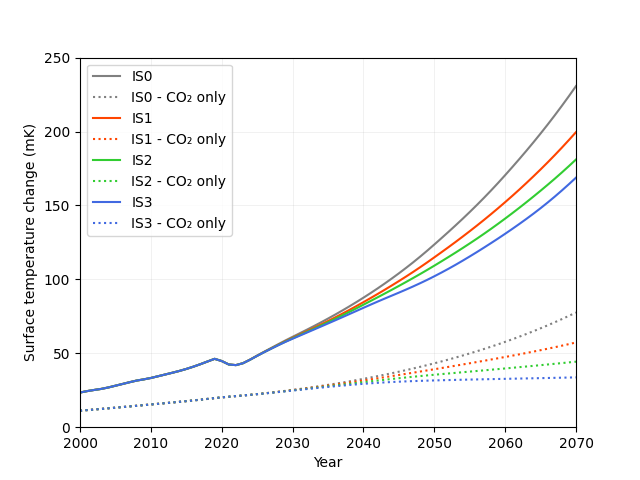

In [13]:
data_years = np.array((range(2000, 2071)))

fig, ax = plt.subplots()

ax.plot(
    data_years,
    1000*process_is0medium_data["climate_outputs"][["temperature_increase_from_aviation"]].values[
        2000 - 1940 : 2070 - 1940 + 1
    ],
    color="grey",
    linestyle="-",
    label="IS0",
)

ax.plot(
    data_years,
    1000*process_is0medium_data["climate_outputs"][
        ["temperature_increase_from_co2_from_aviation"]
    ].values[2000 - 1940 : 2070 - 1940 + 1],
    color="grey",
    linestyle=":",
    label="IS0 - CO₂ only",
)

ax.plot(
    data_years,
    1000*process_is1medium_data["climate_outputs"][["temperature_increase_from_aviation"]].values[
        2000 - 1940 : 2070 - 1940 + 1
    ],
    color="orangered",
    linestyle="-",
    label="IS1",
)

ax.plot(
    data_years,
    1000*process_is1medium_data["climate_outputs"][
        ["temperature_increase_from_co2_from_aviation"]
    ].values[2000 - 1940 : 2070 - 1940 + 1],
    color="orangered",
    linestyle=":",
    label="IS1 - CO₂ only",
)

ax.plot(
    data_years,
    1000*process_is2medium_data["climate_outputs"][["temperature_increase_from_aviation"]].values[
        2000 - 1940 : 2070 - 1940 + 1
    ],
    color="limegreen",
    linestyle="-",
    label="IS2",
)

ax.plot(
    data_years,
    1000*process_is2medium_data["climate_outputs"][
        ["temperature_increase_from_co2_from_aviation"]
    ].values[2000 - 1940 : 2070 - 1940 + 1],
    color="limegreen",
    linestyle=":",
    label="IS2 - CO₂ only",
)

ax.plot(
    data_years,
    1000*process_is3medium_data["climate_outputs"][["temperature_increase_from_aviation"]].values[
        2000 - 1940 : 2070 - 1940 + 1
    ],
    color="royalblue",
    linestyle="-",
    label="IS3",
)

ax.plot(
    data_years,
    1000*process_is3medium_data["climate_outputs"][
        ["temperature_increase_from_co2_from_aviation"]
    ].values[2000 - 1940 : 2070 - 1940 + 1],
    color="royalblue",
    linestyle=":",
    label="IS3 - CO₂ only",
)

ax.set(
    xlabel="Year",
    ylabel="Surface temperature change (mK)",
)
ax.grid(alpha=0.25, linewidth=0.5)
plt.xlim(2000, 2070)
plt.ylim(0, 250)
plt.legend()
plt.show()

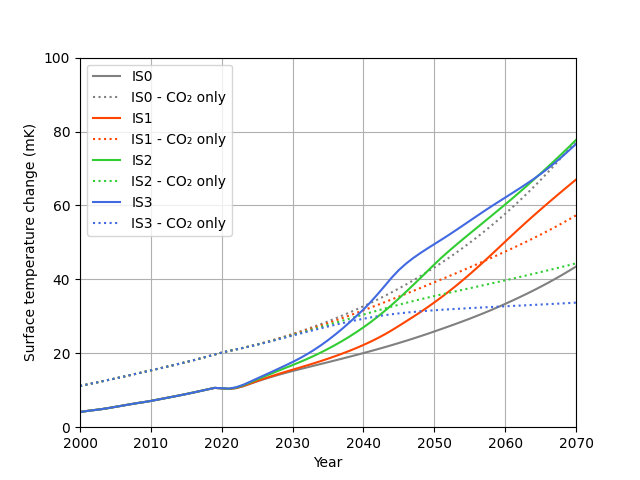

In [14]:
data_years = np.array((range(2000, 2071)))

fig, ax = plt.subplots()

ax.plot(
    data_years,
    1000*process_is0medium_update_data["climate_outputs"][["temperature_increase_from_aviation"]].values[
        2000 - 1940 : 2070 - 1940 + 1
    ],
    color="grey",
    linestyle="-",
    label="IS0",
)

ax.plot(
    data_years,
    1000*process_is0medium_update_data["climate_outputs"][
        ["temperature_increase_from_co2_from_aviation"]
    ].values[2000 - 1940 : 2070 - 1940 + 1],
    color="grey",
    linestyle=":",
    label="IS0 - CO₂ only",
)

ax.plot(
    data_years,
    1000*process_is1medium_update_data["climate_outputs"][["temperature_increase_from_aviation"]].values[
        2000 - 1940 : 2070 - 1940 + 1
    ],
    color="orangered",
    linestyle="-",
    label="IS1",
)

ax.plot(
    data_years,
    1000*process_is1medium_update_data["climate_outputs"][
        ["temperature_increase_from_co2_from_aviation"]
    ].values[2000 - 1940 : 2070 - 1940 + 1],
    color="orangered",
    linestyle=":",
    label="IS1 - CO₂ only",
)

ax.plot(
    data_years,
    1000*process_is2medium_update_data["climate_outputs"][["temperature_increase_from_aviation"]].values[
        2000 - 1940 : 2070 - 1940 + 1
    ],
    color="limegreen",
    linestyle="-",
    label="IS2",
)

ax.plot(
    data_years,
    1000*process_is2medium_update_data["climate_outputs"][
        ["temperature_increase_from_co2_from_aviation"]
    ].values[2000 - 1940 : 2070 - 1940 + 1],
    color="limegreen",
    linestyle=":",
    label="IS2 - CO₂ only",
)

ax.plot(
    data_years,
    1000*process_is3medium_update_data["climate_outputs"][["temperature_increase_from_aviation"]].values[
        2000 - 1940 : 2070 - 1940 + 1
    ],
    color="royalblue",
    linestyle="-",
    label="IS3",
)

ax.plot(
    data_years,
    1000*process_is3medium_update_data["climate_outputs"][
        ["temperature_increase_from_co2_from_aviation"]
    ].values[2000 - 1940 : 2070 - 1940 + 1],
    color="royalblue",
    linestyle=":",
    label="IS3 - CO₂ only",
)

ax.set(
    xlabel="Year",
    ylabel="Surface temperature change (mK)",
)
ax.grid()
plt.xlim(2000, 2070)
plt.ylim(0, 100)
plt.legend()
plt.show()

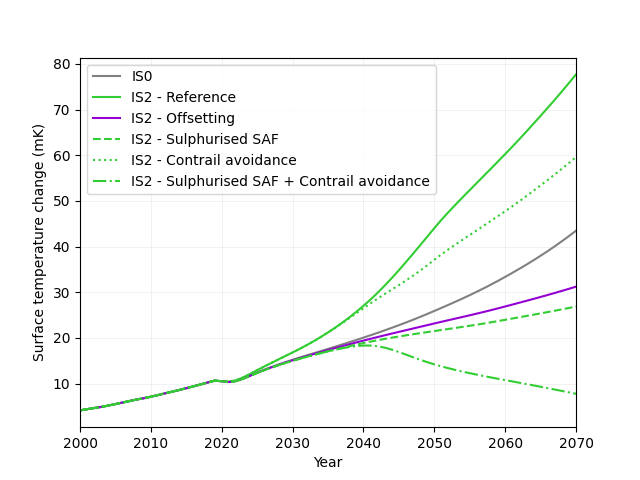

In [15]:
data_years = np.array((range(2000, 2071)))

fig, ax = plt.subplots()

ax.plot(
    data_years,
    1000*process_is0medium_update_sulfur_data["climate_outputs"][["temperature_increase_from_aviation"]].values[
        2000 - 1940 : 2070 - 1940 + 1
    ],
    color="grey",
    linestyle="-",
    label="IS0",
)

ax.plot(
    data_years,
    1000*process_is2medium_update_data["climate_outputs"][["temperature_increase_from_aviation"]].values[
        2000 - 1940 : 2070 - 1940 + 1
    ],
    color="limegreen",
    linestyle="-",
    label="IS2 - Reference",
)

#ax.plot(
#    data_years,
#    1000*process_is2medium_update_kero_data["climate_outputs"][["temperature_increase_from_aviation"]].values[
#        2000 - 1940 : 2070 - 1940 + 1
#    ],
#    color="black",
#    linestyle="-",
#    label="IS2 - Kerosene",
#)

ax.plot(
    data_years,
    1000*process_is2medium_update_dac_data["climate_outputs"][["temperature_increase_from_aviation"]].values[
        2000 - 1940 : 2070 - 1940 + 1
    ],
    color="darkviolet",
    linestyle="-",
    label="IS2 - Offsetting",
)

ax.plot(
    data_years,
    1000*process_is2medium_update_sulfur_data["climate_outputs"][["temperature_increase_from_aviation"]].values[
        2000 - 1940 : 2070 - 1940 + 1
    ],
    color="limegreen",
    linestyle="--",
    label="IS2 - Sulphurised SAF",
)

ax.plot(
    data_years,
    1000*process_is2medium_update_contrails_data["climate_outputs"][["temperature_increase_from_aviation"]].values[
        2000 - 1940 : 2070 - 1940 + 1
    ],
    color="limegreen",
    linestyle=":",
    label="IS2 - Contrail avoidance",
)

ax.plot(
    data_years,
    1000*process_is2medium_update_sulfur_contrails_data["climate_outputs"][["temperature_increase_from_aviation"]].values[
        2000 - 1940 : 2070 - 1940 + 1
    ],
    color="limegreen",
    linestyle="-.",
    label="IS2 - Sulphurised SAF + Contrail avoidance",
)


ax.set(
    xlabel="Year",
    ylabel="Surface temperature change (mK)",
)
ax.grid(alpha=0.25, linewidth=0.5)
plt.xlim(2000, 2070)
plt.legend()
plt.show()

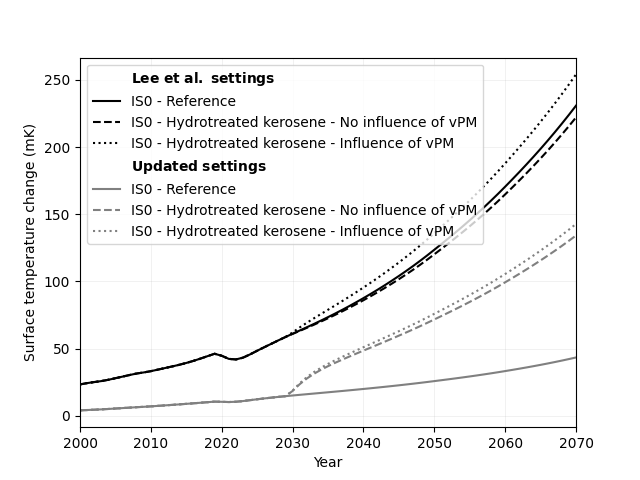

In [16]:
data_years = np.array((range(2000, 2071)))

fig, ax = plt.subplots()

ax.plot([], [], color="none", label=r"$\bf{Lee\ et\ al.\ settings}$")

ax.plot(
    data_years,
    1000*process_is0medium_data["climate_outputs"][["temperature_increase_from_aviation"]].values[
        2000 - 1940 : 2070 - 1940 + 1
    ],
    color="black",
    linestyle="-",
    label="IS0 - Reference",
)

ax.plot(
    data_years,
    1000*process_is0medium_keroht_data["climate_outputs"][["temperature_increase_from_aviation"]].values[
        2000 - 1940 : 2070 - 1940 + 1
    ],
    color="black",
    linestyle="--",
    label="IS0 - Hydrotreated kerosene - No influence of vPM",
)

ax.plot(
    data_years,
    1000*process_is0medium_keroht_vpm_data["climate_outputs"][["temperature_increase_from_aviation"]].values[
        2000 - 1940 : 2070 - 1940 + 1
    ],
    color="black",
    linestyle=":",
    label="IS0 - Hydrotreated kerosene - Influence of vPM",
)

ax.plot([], [], color="none", label=r"$\bf{Updated\ settings}$")

ax.plot(
    data_years,
    1000*process_is0medium_update_data["climate_outputs"][["temperature_increase_from_aviation"]].values[
        2000 - 1940 : 2070 - 1940 + 1
    ],
    color="grey",
    linestyle="-",
    label="IS0 - Reference",
)

ax.plot(
    data_years,
    1000*process_is0medium_update_keroht_data["climate_outputs"][["temperature_increase_from_aviation"]].values[
        2000 - 1940 : 2070 - 1940 + 1
    ],
    color="grey",
    linestyle="--",
    label="IS0 - Hydrotreated kerosene - No influence of vPM",
)

ax.plot(
    data_years,
    1000*process_is0medium_update_keroht_vpm_data["climate_outputs"][["temperature_increase_from_aviation"]].values[
        2000 - 1940 : 2070 - 1940 + 1
    ],
    color="grey",
    linestyle=":",
    label="IS0 - Hydrotreated kerosene - Influence of vPM",
)


ax.set(
    xlabel="Year",
    ylabel="Surface temperature change (mK)",
)
ax.grid(alpha=0.25, linewidth=0.5)
plt.xlim(2000, 2070)
plt.legend()
plt.show()

In [17]:
process_is2medium_update.write_excel(file_name="aeromaps_data.xlsx")

In [18]:
process_is2medium_update_sulfur.write_excel(file_name="aeromaps_data_sulfur.xlsx")

In [19]:
process_is2medium_update_sulfur_contrails.write_excel(file_name="aeromaps_data_sulfur_contrails.xlsx")